# WASP-39 b with NIRSpec/G395H: two detectors and a jump in the flux

The ERS transit programme (ERS 1366) also observed WASP-39 b with the
NIRSpec high-resolution grating G395H, 2.7-5.2 µm, which disperses the
spectrum over two detectors, NRS1 and NRS2. The transit confirmed the CO$_2$
feature at 4.3 µm and showed SO$_2$ at 4.05 µm (Alderson et al. 2023, Nature
614, 664).

The light curves of this visit have a **jump**. During integration 269 one
of the JWST primary-mirror segments tilted. The PSF suddenly became wider
and stayed so, and the flux in a fixed aperture dropped by about 0.2%, in
the middle of the transit. Such events (mirror tilts, high-gain-antenna
moves, guide-star changes) happen in many visits. This tutorial shows:

* how the jump shows up in the extraction, and why one PSF for the whole
  exposure is then wrong (it biased the depths by up to 340 ppm);
* the fix: **PSF epochs**, `ex.set('psf', breaks=[...])`, and the warning
  that tells you when you need them;
* how to fit light curves across the jump (a step regressor, and which
  integrations to drop);
* that the result reproduces the published spectra on both detectors.

The [PRISM tutorial](wasp39b_prism.ipynb) explains the stages that work the
same way (1/f noise, cosmic rays, the PSF model, the pixel-response map);
here we concentrate on what differs.

**Contents**

1. Stage 1 on segment 2 of NRS1 (run here)
2. Wavelength map and cleaning
3. Extraction across the tilt: one PSF, then two epochs
4. The full exposure, both detectors
5. White-light fits with a step
6. Transmission spectrum
7. Summary: how to handle a jump

## The data

| | |
| --- | --- |
| Programme | JWST ERS 1366, observation 3 (30-31 July 2022) |
| Mode | NIRSpec BOTS, G395H/F290LP, SUB2048, NRSRAPID, detectors NRS1 and NRS2 |
| Read-out | 70 groups (0.90 s each), 63 s per integration |
| Integrations | 465, in 3 segments of 155 (8.3 h; transit duration 2.8 h) |
| Files | `jw01366003001_04101_00001-seg00[1-3]_nrs[1-2]_uncal.fits` (4.3 GB per detector) |

```python
from astroquery.mast import Observations

obs = Observations.query_criteria(obs_collection='JWST', proposal_id='1366',
                                  instrument_name='NIRSPEC/SLIT')
prods = Observations.filter_products(Observations.get_product_list(obs),
                                     productSubGroupDescription='UNCAL')
for det in ('nrs1', 'nrs2'):
    keep = [f.startswith('jw01366003001_04101') and f.endswith(f'_{det}_uncal.fits')
            for f in prods['productFilename']]
    Observations.download_products(prods[keep], download_dir=DATA[det.upper()], flat=True)
```

The two detectors record different wavelengths of the same exposure, at
the same times. jstark treats them as two independent exposures: one folder
of `uncal` files and one set of products each.

## Setup

`DATA` holds the `uncal` folder of each detector. This notebook writes the
products of one segment to `TUT`; `FULL` holds the products of the whole
exposures, made with the cell in Section 4. `PUB` holds the published light
curves and spectra used for the comparisons: the ERS benchmark (Carter & May
et al. 2024, Zenodo) and Alderson et al. (2023, Zenodo 7185300).

In [1]:
import os
import glob
import warnings
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
from astropy.io import fits
from astropy.table import Table

from jstark.reduction import Stage1, Stage2, ExposureCleaner
from jstark.reduction import diagnostics as rdiag
from jstark.extraction import SpectralExtractor, Spectra
from jstark.extraction import diagnostics as xdiag
from jstark.extraction.metrics import find_psf_breaks
from jstark.fitting import LightCurves, BroadbandFit, SpectroscopicFit, Spectrum

BASE = '/Volumes/Jayshil SSD/JWST/jwst-ers'
DATA = {d: f'{BASE}/Data/NRSG395H_{d}' for d in ('NRS1', 'NRS2')}   # the uncal files
OUT = f'{BASE}/NRSG395H/Outputs'
TUT = f'{OUT}/tutorial'                       # segment 2 of NRS1 (this notebook)
FULL = {d: f'{OUT}/{d}' for d in DATA}        # the full exposures
PUB = f'{OUT}/published'
ROOT = 'jw01366003001_04101_00001'
TILT = 269            # integration (0-based) during which the mirror segment tilted
RUN_FULL = False      # True re-runs the full exposures (20 min) and the fits (2.5 h)

from jstark.plotting import use_style
use_style()
%config InlineBackend.figure_formats = ['retina']
os.makedirs(TUT, exist_ok=True)

## 1. Stage 1 on segment 2

The tilt happened during integration 269, in the second segment
(integrations 155-309). To see it in a test run, we process that segment of
NRS1 only. The recipe is the NIRSpec default (see the PRISM tutorial); the
only change is to limit the ramp fit to 4 processes, because a 70-group
segment of the full 2048-column subarray takes several GB per process.

In [2]:
s1 = Stage1(DATA['NRS1'], outdir=TUT)
s1.set('ramp_fit', maximum_cores='4')
s1.show()

jstark Stage1: NIRSpec/G395H | exposure jw01366003001_04101_00001_nrs1 | 3 segment(s) | output -> /Volumes/Jayshil SSD/JWST/jwst-ers/NRSG395H/Outputs/tutorial
Recipe for NIRSpec/G395H:
   0. [run ] jwst   group_scale          
   1. [run ] jwst   dq_init              
   2. [run ] jwst   saturation           {'n_pix_grow_sat': 1}
   3. [run ] jstark consistent_saturation {'min_frac': 0.01, 'scope': 'exposure'}
   4. [run ] jwst   superbias            
   5. [SKIP] jstark custom_bias          {'method': 'scaled', 'mode': 'smooth'}
   6. [run ] jwst   refpix               
   7. [run ] jstark group_bkg            {'method': 'median', 'axis': 'column'}
   8. [run ] jwst   linearity            
   9. [SKIP] jwst   dark_current         
  10. [SKIP] jwst   charge_migration     
  11. [SKIP] jwst   jump                 {'rejection_threshold': 15.0, 'maximum_cores': 'half'}
  12. [run ] jstark temporal_jump        {'window': 11, 'threshold': 10.0, 'mode': 'auto'}
  13. [SKIP] jwst   clean_fli

### 1.1 The saturation map and static bad pixels

WASP-39 does not saturate in 63 s with G395H. The saturation pre-pass
still finds a few pixels: 3×3 blocks around *static* bad pixels of the CRDS
bad-pixel mask (dead, hot, low quantum efficiency). The jwst `saturation`
step flags those pixels (often already in group 0) and grows the flag onto
their neighbours (`n_pix_grow_sat=1`). jstark leaves them out of the
saturation map: they are not saturation by the star, and they are handled
as bad pixels by the cleaning. They are saved in the map's `STATIC`
extension. (Two pixels remain in the map from this one segment; with all
three segments, NRS1 has none.)

In [3]:
satmap = s1.compute_saturation_map(segments=[1])
ng = int(satmap.max())
with fits.open(f'{TUT}/{ROOT}_nrs1_saturation_map.fits') as h:
    static = h['STATIC'].data
print(f'{ng} groups; pixels saturated by the scene: {np.sum(satmap < ng)}; '
      f'static bad pixels (and grown neighbours) left out: {np.sum(static < ng)}')

  saturation pre-pass: segment 2/3
  saturation map: 2 pixels saturate (in >= 1% of integrations); first saturated group histogram [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 65534]
  saturation map: 18 more pixels are static bad pixels (DO_NOT_USE) or flagged only by growth around them; left out (STATIC extension)
70 groups; pixels saturated by the scene: 2; static bad pixels (and grown neighbours) left out: 18


<div class="alert alert-info">

**Why static bad pixels are left out of the saturation map**

The first full run of these data used them. NRS2 then had 225 "saturated"
pixels, 3×3 blocks around 25 bad pixels. The extraction's `min_groups=2`
(a column whose aperture keeps fewer than two groups has no reliable flux)
set **13 columns of NRS2 to NaN for the whole exposure**, holes in the
spectrum where nothing was wrong with the star. With the static pixels left
out, NRS1 has no saturated pixels and NRS2 has 9 (one hot pixel missing
from the CRDS mask, outside the aperture), and no column is lost. The
Stage 1 processing is unchanged: `consistent_saturation` still flags those
groups.

</div>

### 1.2 Running Stage 1, and cosmic rays with 70 groups

With 10 or more groups, `temporal_jump` *flags* a cosmic ray between two
groups (the ramp fit then splits the ramp there) instead of replacing the
group difference. With 70 groups, a 63 s integration catches many more
cosmic rays than the short PRISM integrations. This segment takes about
3 minutes.

In [4]:
%%time
rateints = s1.run(segments=[1])
diag = rdiag.load_stage1_diagnostics(rateints[0].replace('_rateints.fits', '_stage1diag.npz'))
j = diag['temporal_jump']
print(f"{int(j['n_jumps'])} jumps in {len(j['frac_per_int'])} integrations: "
      f"{100 * np.median(j['frac_per_int']):.2f}% of the pixels per integration")

Segment 2/3: jw01366003001_04101_00001-seg002_nrs1_uncal.fits


    group_scale          done in    0.3 s


    dq_init              done in    0.5 s


    saturation           done in    3.0 s


    consistent_saturation: 20 pixels, 5742 saturated-group flags added
    consistent_saturation done in    0.8 s


    superbias            done in    0.4 s


... (4 outputs left out)

    temporal_jump: 35205 jumps (flag), median fraction of pixels hit per integration = 0.343%
    temporal_jump        done in   79.8 s


    ramp_fit             done in   20.6 s
    gain_scale           done in    0.1 s


  -> /Volumes/Jayshil SSD/JWST/jwst-ers/NRSG395H/Outputs/tutorial/jw01366003001_04101_00001-seg002_nrs1_rateints.fits  (161.0 s)


35205 jumps in 155 integrations: 0.34% of the pixels per integration
CPU times: user 2min 12s, sys: 10.7 s, total: 2min 23s
Wall time: 2min 41s


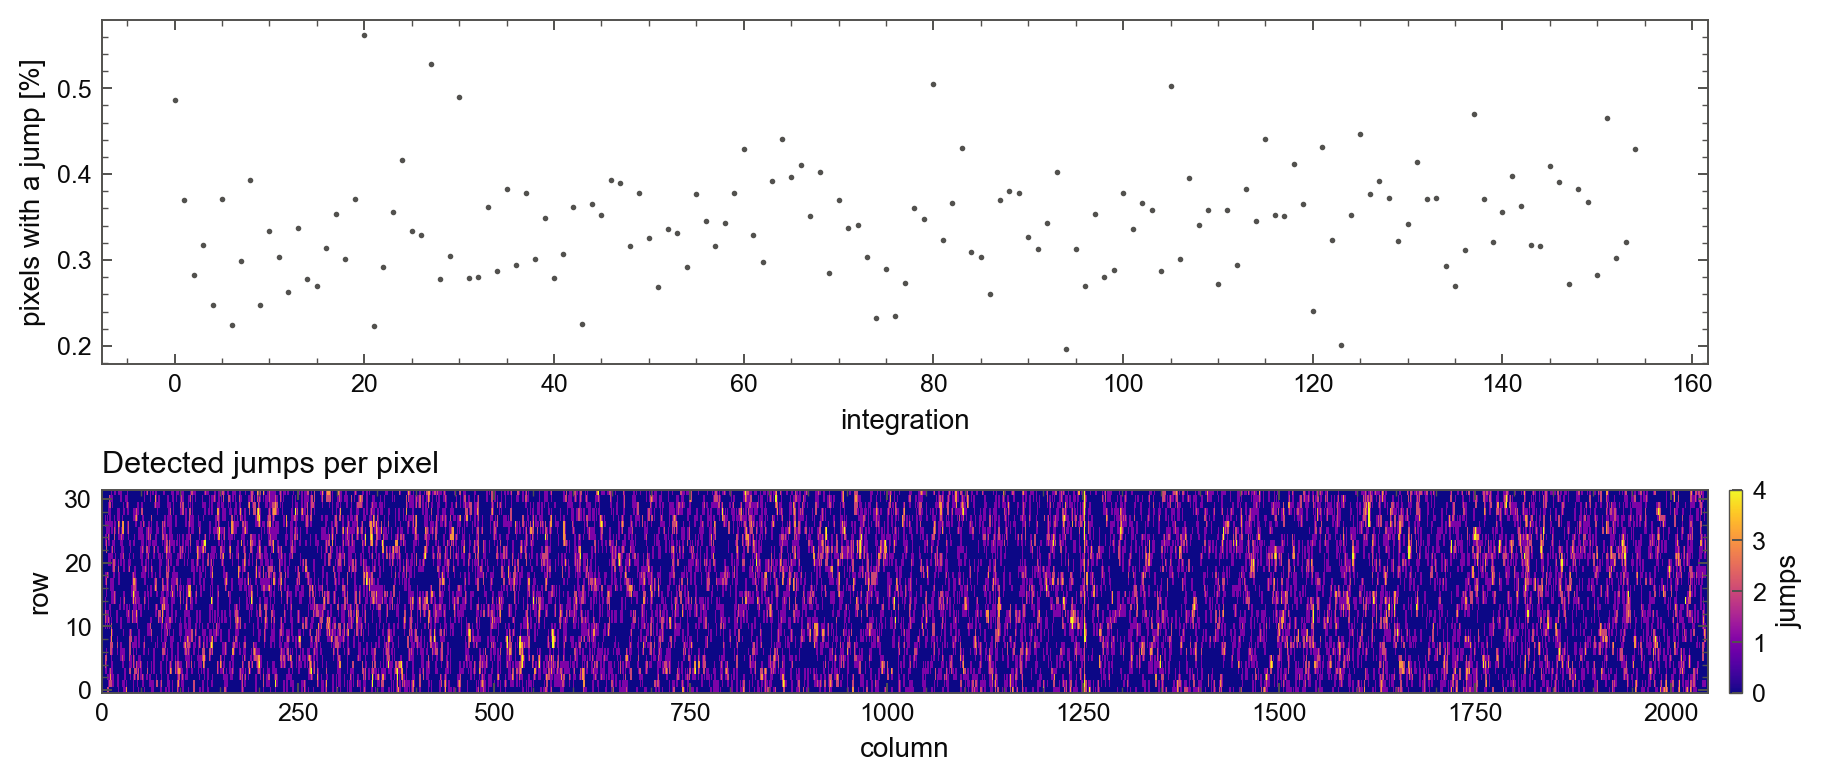

In [5]:
rdiag.plot_jumps(j['frac_per_int'], j['jump_count_map']);

About 0.33% of the pixels per integration. That is the expected rate: about
5 cosmic rays per cm² per second hit the 0.21 cm² of the subarray, about
65 events in 63 s, each affecting 2-3 pixels per frame and more as charge
spreads. The jumps are spread evenly in time and over the detector.

## 2. Wavelength map and cleaning

These work as for PRISM. The cleaning flags about 160 transient pixels per
integration, mostly cosmic rays too faint for the group-level test.

In [6]:
wfile = Stage2(TUT).run()['wavelength']
info = ExposureCleaner(TUT, wavelength=wfile).run()
cc = ExposureCleaner.load(info).load_segment(0)
cc.summary()

Wavelength map (32, 2048): 2.334-3.722 micron
Saved wavelength map to /Volumes/Jayshil SSD/JWST/jwst-ers/NRSG395H/Outputs/tutorial/jw01366003001_04101_00001_nrs1_wavelength.fits
ExposureCleaner: NIRSpec/G395H | jw01366003001_04101_00001_nrs1 | 1 segment(s), 155 integrations


  pass 1: segment 1/1 read
compute_global: 547 bad pixels from DQ, 220 hot/noisy pixels; trace mask 51.7% of pixels


  segment 1/1: 25341 transient flags (163.5 per integration) -> jw01366003001_04101_00001-seg002_nrs1_cleaned.fits
Saved exposure info to /Volumes/Jayshil SSD/JWST/jwst-ers/NRSG395H/Outputs/tutorial/jw01366003001_04101_00001_nrs1_cleaninfo.fits
NIRSpec/G395H: (155, 32, 2048); persistent bad pixels: 767 (1.17%); transient flags: 25341 (0.2495%, 163.5 per integration)


'NIRSpec/G395H: (155, 32, 2048); persistent bad pixels: 767 (1.17%); transient flags: 25341 (0.2495%, 163.5 per integration)'

## 3. Extraction across the tilt

### 3.1 With one PSF (the default)

First the default extraction: one PSF model and one pixel-response map for
all integrations. We write it to a separate folder.

In [7]:
%%time
ex1 = SpectralExtractor(info, outdir=f'{TUT}/one_psf')
os.makedirs(ex1.outdir, exist_ok=True)
ex1.find_trace()
ex1.fit_psf()
with warnings.catch_warnings():
    warnings.simplefilter('ignore')       # the warning is also written to the log (WARNING line)
    seg1 = ex1.run()

SpectralExtractor: NIRSpec/G395H | jw01366003001_04101_00001_nrs1 | 1 segment(s), 155 integrations | orders [1]
  order 1: columns 488-2042, 2.666-3.718 um; trace rows 11.17-21.42; centroid rms about the fit 0.008 px


  order 1: first PSF from 155 integrations; residual scale 1.38 sigma; 0.111% of pixels rejected


  order 1: PSF pass 1: 3353135 pixels from 155 integrations, 744 coefficients, smoothing (u, x) = (2e-05, 2e+00), reduced chi2 4.727, rejected 0.112%
  pixel-response map: 21713 pixels, rms 0.0307
fit_psf done in 9 s


  segment 1/1: 155 integrations; order 1: 647.2 rejected px/int, dy rms 7.4 mpx
extraction done in 5 s
Saved spectra to /Volumes/Jayshil SSD/JWST/jwst-ers/NRSG395H/Outputs/tutorial/one_psf/jw01366003001_04101_00001_nrs1_spectra.fits
CPU times: user 19 s, sys: 17.6 s, total: 36.6 s
Wall time: 14.7 s


The extraction warns (the WARNING line of the log) that the PSF changed
abruptly at integration 116 of this segment, 271 of the exposure. The step
finder lands just after the tilt, because integration 269 is a mix of both
PSFs and 270 had not fully settled. The tilt itself happened during
integration 269. The extractor counts integrations from the first one it
was given, so that is number 269 − 155 = 114 here (on the full exposure it
is 269). The regressors show what happened:

In [8]:
G0 = 155                                     # first integration of segment 2

def tilt_panels(runs, xlim=None):
    '''ds, rejected pixels, extraction chi2 and optimal/box white light against integration.'''
    fig, axs = plt.subplots(4, 1, figsize=(9, 7.5), sharex=True, layout='constrained')
    for (name, s, g0), col in zip(runs, ('#898781', 'C0', 'C1')):
        r, g = s.regressors[1], s.gidx + g0
        ratio = s.white_light(method='optimal')[0] / s.white_light(method='box')[0]
        pre = (g >= 15) & (g < TILT)
        axs[0].plot(g, r['ds'], '-', color=col, lw=0.9, label=name)
        axs[1].plot(g, r['nrej'], '-', color=col, lw=0.9)
        axs[2].plot(g, r['chi2'], '-', color=col, lw=0.9)
        k = g != TILT                            # integration 269 is percent-level off: not shown
        axs[3].plot(g[k], 1e6 * (ratio[k] / np.median(ratio[pre]) - 1), '.', color=col, ms=3)
    axs[1].set_yscale('symlog', linthresh=10)
    for a, lab in zip(axs, ('width change ds', 'rejected pixels', 'extraction χ²',
                            'optimal / box − 1 [ppm]')):
        a.axvline(TILT, color='#eda100', lw=1.2, zorder=0)
        a.set_ylabel(lab)
    axs[0].legend(loc='upper left')
    axs[-1].set_xlabel('integration (exposure numbering)')
    if xlim:
        axs[-1].set_xlim(*xlim)
    fig.align_ylabels(axs)
    return fig

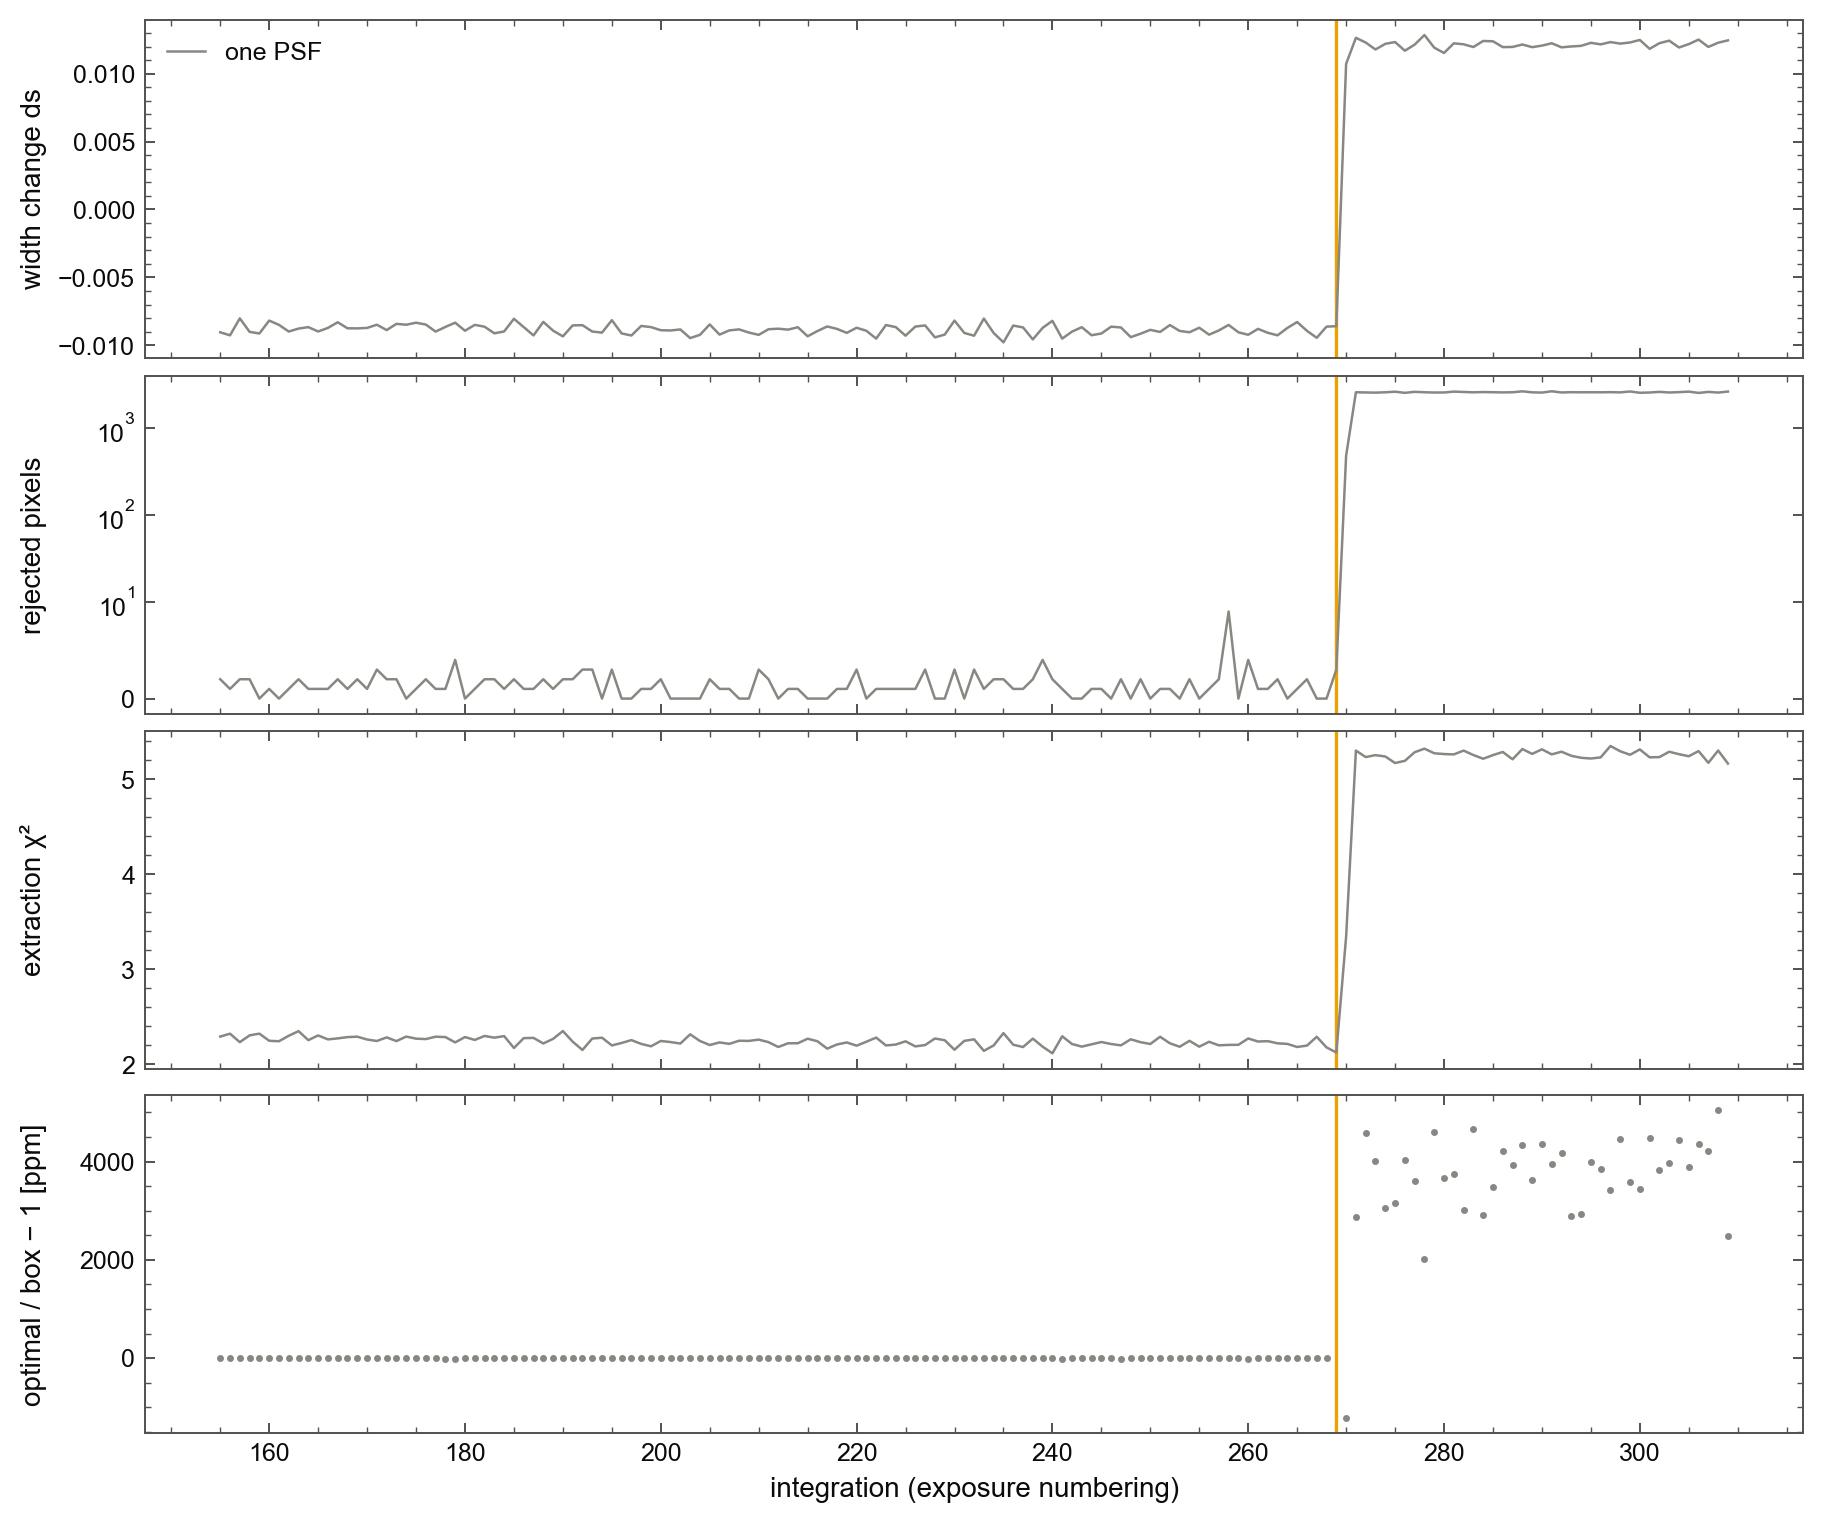

In [9]:
tilt_panels([('one PSF', seg1, G0)]);

* **`ds`**, the change of the PSF width fitted in every integration, jumps
  at integration 269 (orange line), and stays there. Integration 269 itself
  is in between: the tilt happened while it was being read.
* **The outlier rejection breaks down.** After the tilt, about 2,500 pixels
  per integration are rejected, most of the aperture. The rejection is
  *temporal*: a pixel is rejected when its residual differs from its own
  median residual over the chunk. That median comes from the 114 integrations
  before the tilt, so after the tilt every pixel whose profile changed looks
  like an outlier.
* **One PSF fits neither side**: the χ² per pixel is about 2 before and 5
  after the tilt, instead of about 1 (4 and 7 on the full exposure).
* **The optimal flux shifts against the box sum** after the tilt, here by
  +3000 to +4500 ppm with a large scatter (on the full exposure, where the
  PSF fit sees more post-tilt integrations, by −250 to −450 ppm). On the
  full exposure this biased the optimal transit depths by +150 to +340 ppm.

### 3.2 What changed: the PSF

The mean cross-dispersion profile before and after the tilt (sum over 200
bright columns, each normalised to unit sum) shows the change directly:

columns 1071-1271; peak fraction 0.3819 -> 0.3728


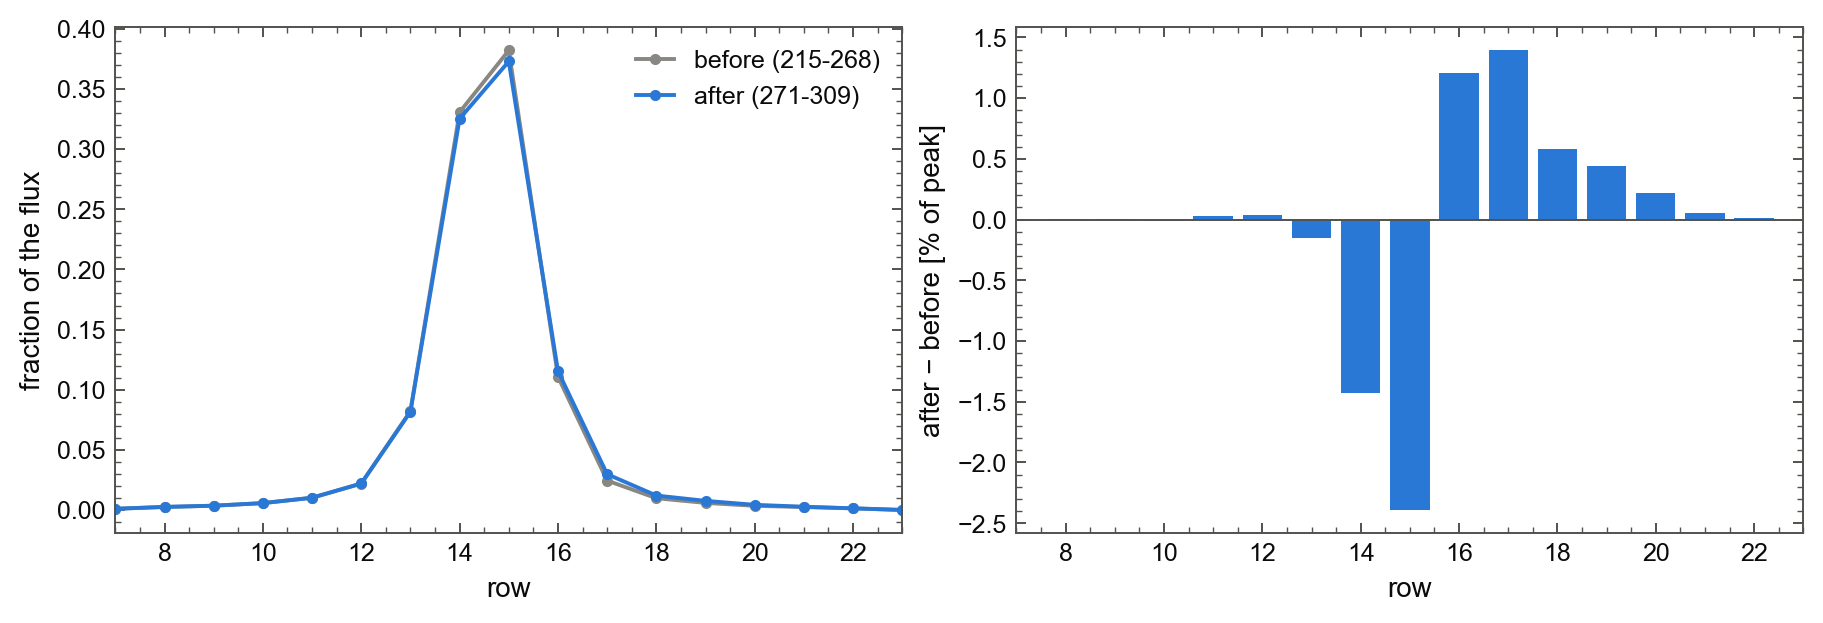

In [10]:
with fits.open(f'{TUT}/{ROOT}-seg002_nrs1_cleaned.fits') as h:
    sci = h['SCI'].data                          # (integration, row, column)
med = np.nanmedian(sci[:100], axis=0)
c0 = int(np.argmax(np.convolve(np.nansum(med, 0), np.ones(200), 'same')))
cols = slice(c0 - 100, c0 + 100)

def profile(ints):
    p = np.nansum(np.nanmedian(sci[ints, :, cols], axis=0), axis=1)
    return p / p.sum()

pre, post = profile(slice(60, 114)), profile(slice(116, 155))
rows = np.arange(sci.shape[1])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3), layout='constrained')
a1.plot(rows, pre, 'o-', ms=3, color='#898781', label='before (215-268)')
a1.plot(rows, post, 'o-', ms=3, color='C0', label='after (271-309)')
a1.set_xlim(rows[np.argmax(pre)] - 8, rows[np.argmax(pre)] + 8)
a1.set_xlabel('row'); a1.set_ylabel('fraction of the flux'); a1.legend()
a2.bar(rows, 1e2 * (post - pre) / pre.max(), color='C0')
a2.set_xlim(*a1.get_xlim()); a2.axhline(0, color='#52514e', lw=0.7)
a2.set_xlabel('row'); a2.set_ylabel('after − before [% of peak]')
print(f'columns {cols.start}-{cols.stop}; peak fraction {pre.max():.4f} -> {post.max():.4f}')

After the tilt the core holds less of the light and the wing on one side
more: the PSF became wider and less symmetric. A box
aperture of fixed width loses the light that moved beyond its edges, so the
box flux drops. A single PSF model, fitted to the average of both sides,
matches neither.

### 3.3 With PSF epochs

`set('psf', breaks=[...])` splits the exposure into **epochs** at the
given integrations. Each epoch gets its own PSF model, pixel-response map
and pixel variances, fitted to that epoch's integrations only, and the
chunks of the extraction (and of the outlier rejection) never cross a
break. The spectra get an `epoch` column among the regressors (0, 1, ...),
ready to use as a step in the light-curve fits.

The new epoch starts at the tilt integration (114 here, 269 on the full
exposure). Integration 269 then belongs to the post-tilt epoch, although it
is a mix of both; it is dropped from the fits anyway.

In [11]:
%%time
ex = SpectralExtractor(info)
ex.set('psf', breaks=[TILT - G0])
ex.find_trace()
ex.fit_psf()
seg = ex.run()
print('epochs (integrations):', [(e['start'] + G0, e['stop'] + G0) for e in ex.epochs])

SpectralExtractor: NIRSpec/G395H | jw01366003001_04101_00001_nrs1 | 1 segment(s), 155 integrations | orders [1]
  order 1: columns 488-2042, 2.666-3.718 um; trace rows 11.17-21.42; centroid rms about the fit 0.008 px
  PSF epoch 1/2: integrations 0-113


  order 1: first PSF from 114 integrations; residual scale 1.00 sigma; 0.002% of pixels rejected


  order 1: PSF pass 1: 2469065 pixels from 114 integrations, 744 coefficients, smoothing (u, x) = (2e-05, 2e-01), reduced chi2 2.293, rejected 0.002%
  pixel-response map: 21680 pixels, rms 0.0295
fit_psf done in 7 s
  PSF epoch 2/2: integrations 114-154


  order 1: first PSF from 41 integrations; residual scale 1.00 sigma; 0.240% of pixels rejected


  order 1: PSF pass 1: 885091 pixels from 41 integrations, 744 coefficients, smoothing (u, x) = (2e-05, 2e-01), reduced chi2 2.474, rejected 0.302%
  pixel-response map: 21710 pixels, rms 0.0249
fit_psf done in 3 s
fit_psf: 2 epochs done in 10 s


  segment 1/1: 155 integrations; order 1: 16.3 rejected px/int, dy rms 10.8 mpx
extraction done in 5 s
Saved spectra to /Volumes/Jayshil SSD/JWST/jwst-ers/NRSG395H/Outputs/tutorial/jw01366003001_04101_00001_nrs1_spectra.fits
epochs (integrations): [(155, 269), (269, 310)]
CPU times: user 25.5 s, sys: 31 s, total: 56.5 s
Wall time: 14.7 s


before the tilt: rejected pixels 1 per integration, chi2 1.04
after  the tilt: rejected pixels 1 per integration, chi2 1.10
integration 269: 2317 rejected pixels


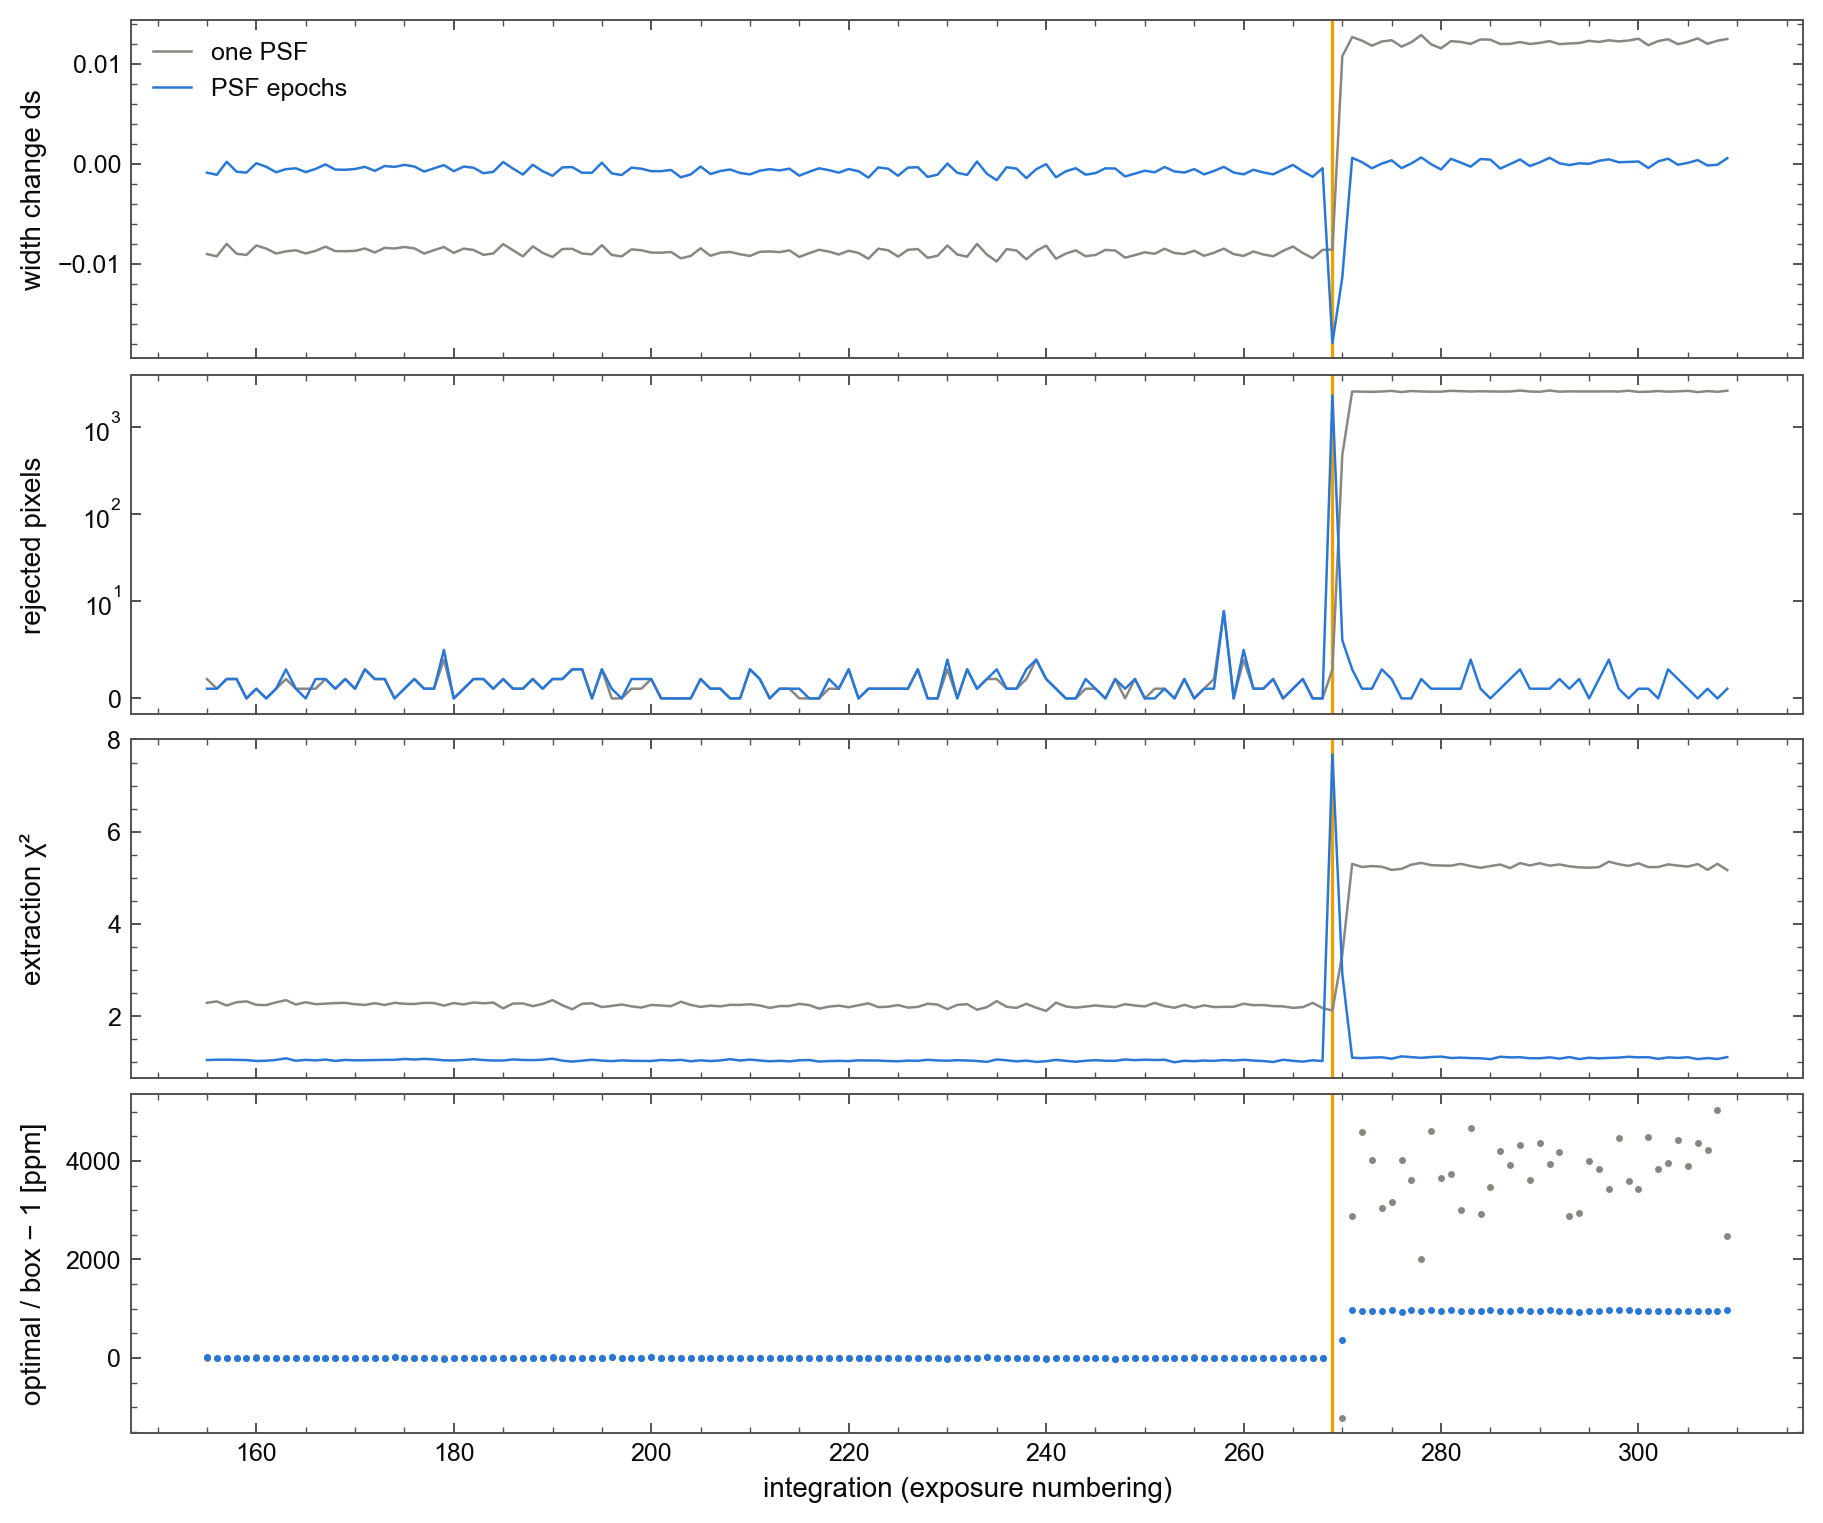

In [12]:
tilt_panels([('one PSF', seg1, G0), ('PSF epochs', seg, G0)]);
r = seg.regressors[1]
g = seg.gidx + G0
for lab, sel in (('before', (g < TILT)), ('after', g > TILT)):
    print(f'{lab:6s} the tilt: rejected pixels {np.median(r["nrej"][sel]):.0f} per integration, '
          f'chi2 {np.median(r["chi2"][sel]):.2f}')
print('integration 269:', int(r['nrej'][g == TILT][0]), 'rejected pixels')

`ds` is now measured against the PSF of each epoch, so it no longer
jumps. With the epochs, the χ² is about 1 on both sides and the rejections are
back to one or two pixels per integration, except in integration 269
itself, which neither PSF fits (its optimal flux is off by about 2%; it
is not shown in the bottom panel). Integration 270 is still slightly off
(+350 ppm in optimal/box): the mirror had not fully settled (Section 5).
The optimal/box ratio is flat within each epoch, with a constant step at
the tilt: the two extractions now differ
only by a constant factor per epoch. The optimal flux drops less than the
box flux at the tilt (about −900 against −1900 ppm on the full exposure).
The profile of each epoch is normalised over the full ±7-pixel extraction
window, so it keeps most of the light the wider PSF moves out of the
±5-pixel box. Either way, the light curve has a step that the fit must
model.

<div class="alert alert-info">

**Why the breaks are set by hand (and when you get a warning)**

`run()` looks for abrupt, lasting changes in the trace position `dy` and
the width `ds` (`jstark.extraction.metrics.find_psf_breaks`): the step of
the median over 5 integrations on either side, in units of its noise, must
exceed 20 and persist for 25 integrations. It warns, with the suggested
`set('psf', breaks=[...])`, when such a step is not covered by a declared
break.

The threshold was calibrated on nine full exposures. The tilt scores 91
(NRS1) and 63 (NRS2) in `ds`. Everything else stays below 10, including
the high-gain-antenna move in the PRISM visit (9.8 in `dy`; that move
affects only 15 integrations, which are dropped). An epoch halves the
data each PSF is fitted to, and the exact break is a judgement call (the
detector suggests 270 here, the integration after the intermediate 269),
so jstark does not split epochs on its own: you decide, after looking at
the regressors.

Breaks are not yet supported with a PSF shared between several exposures
(`VisitExtractor`) or with field-star traces.

</div>

## 4. The full exposure, both detectors

The full exposures were processed with the cell below, one detector after
the other: about 9.5 minutes per detector (Stage 1 8.5 min, cleaning 13 s,
extraction 30 s), with up to 13.5 GB of memory for NRS2. The products take
1.2 GB per detector.

In [13]:
if RUN_FULL:
    for det in ('NRS1', 'NRS2'):
        s1 = Stage1(DATA[det], outdir=FULL[det])
        s1.set('ramp_fit', maximum_cores='4')
        s1.run()
        wf = Stage2(FULL[det]).run()['wavelength']
        inf = ExposureCleaner(FULL[det], wavelength=wf).run()
        exf = SpectralExtractor(inf)
        exf.set('psf', breaks=[TILT])
        exf.find_trace()
        exf.fit_psf()
        exf.run()

In [14]:
spec = {d: Spectra(f'{FULL[d]}/{ROOT}_{d.lower()}_spectra.fits') for d in FULL}
# the first extraction, without breaks, kept for comparison
spec_one = {d: Spectra(f'{OUT}/tests/{d}_default_nobreak/{ROOT}_{d.lower()}_spectra.fits') for d in FULL}
for d, s in spec.items():
    print(d, s.flux[1].shape, '(integrations, columns),',
          f'{s.wavelength[1].min():.3f}-{s.wavelength[1].max():.3f} micron')

NRS1 (465, 1555) (integrations, columns), 2.666-3.718 micron
NRS2 (465, 2039) (integrations, columns), 3.823-5.175 micron


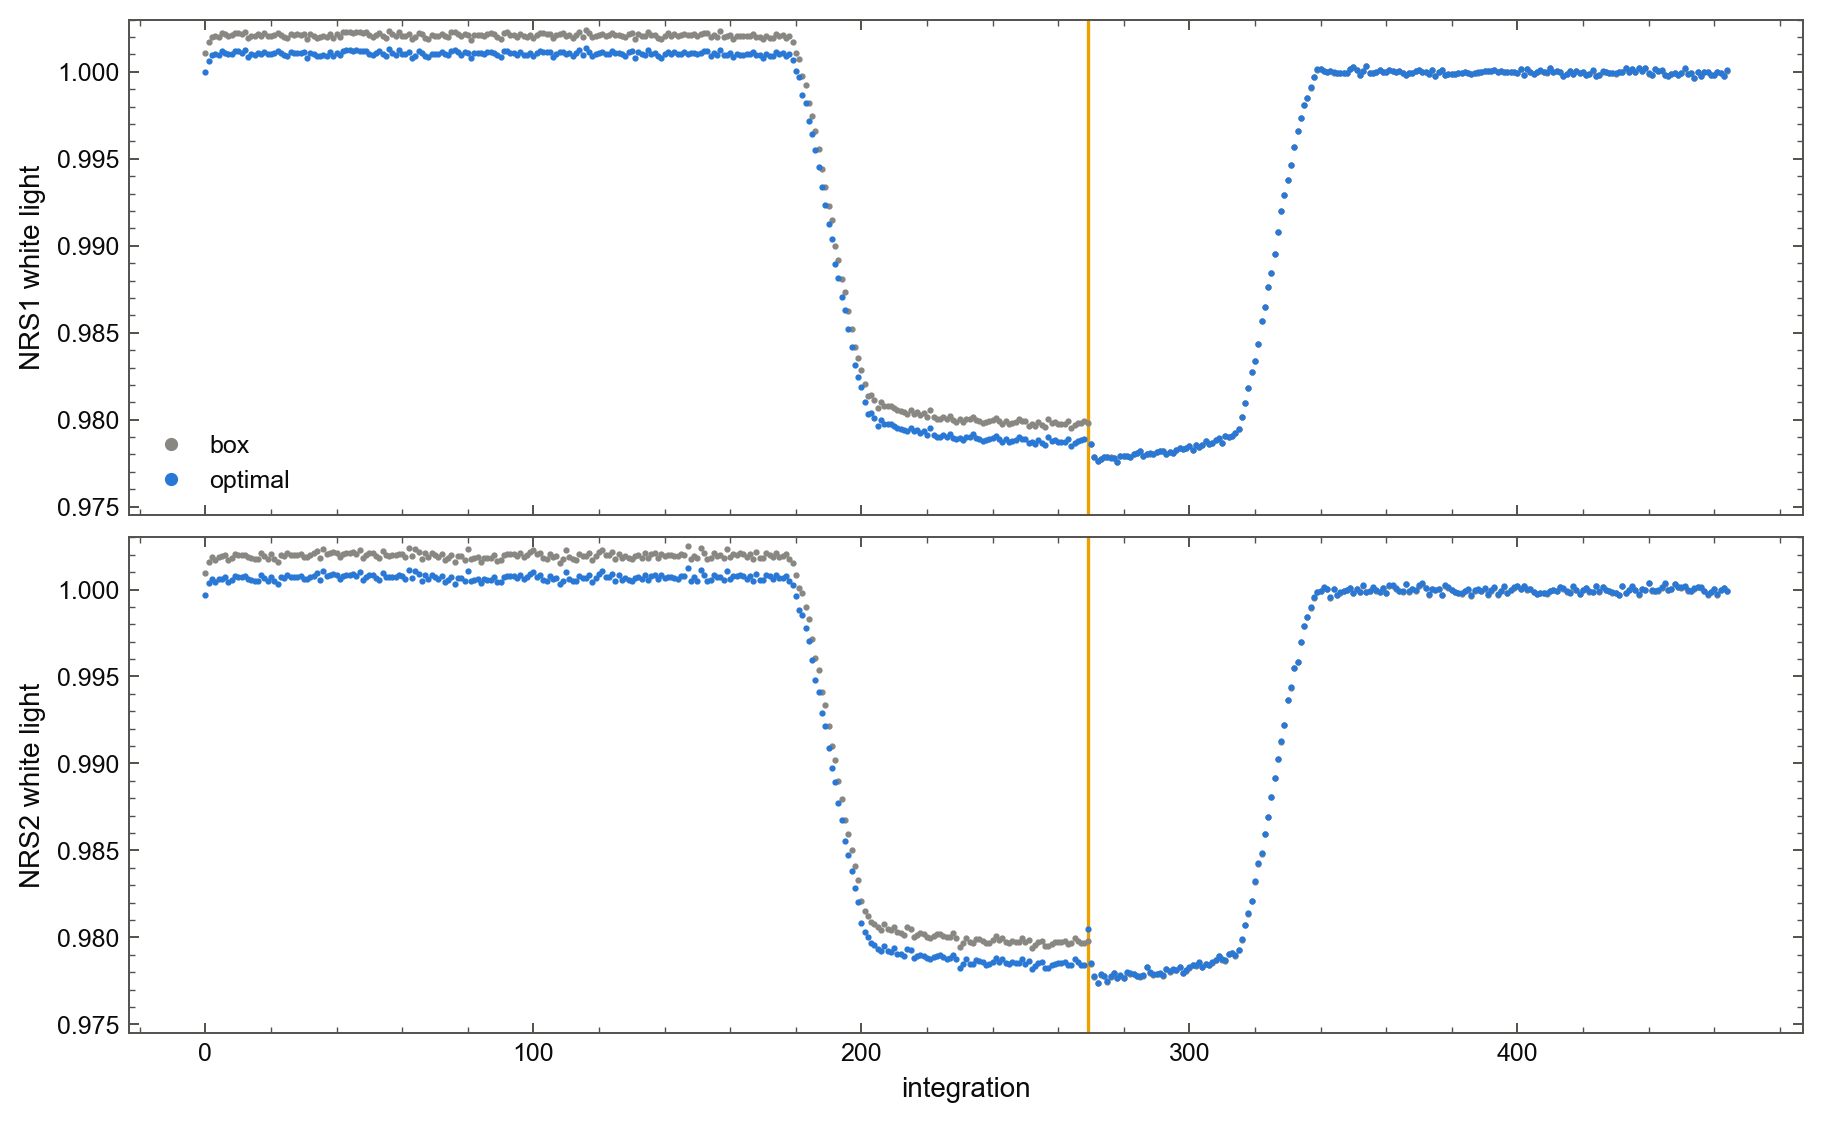

In [15]:
fig, axs = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True, layout='constrained')
for a, d in zip(axs, spec):
    s = spec[d]
    for method, col in (('box', '#898781'), ('optimal', 'C0')):
        f, _ = s.white_light(method=method)
        a.plot(s.gidx, f, '.', ms=2.5, color=col, label=method)
    a.axvline(TILT, color='#eda100', lw=1.2, zorder=0)
    a.set_ylabel(f'{d} white light')
    a.set_ylim(0.9745, 1.003)
axs[0].legend(loc='lower left', markerscale=3)
axs[-1].set_xlabel('integration');

The jump is visible by eye in the flat bottom of the transit, on both
detectors: about −1900 ppm in the box flux and −900 / −700 ppm (NRS1 /
NRS2) in the optimal flux. Mid-transit is at integration ~259, so the jump
falls right where the depth is measured. A fit without a step would bias the
depth by roughly half the jump.

The break finder on the full exposures without breaks, and the effect of
the epochs on the optimal/box ratio:

NRS1: step in ds at integration 271, score 66
NRS1: step in ds at integration 309, score 28
NRS2: step in ds at integration 271, score 61


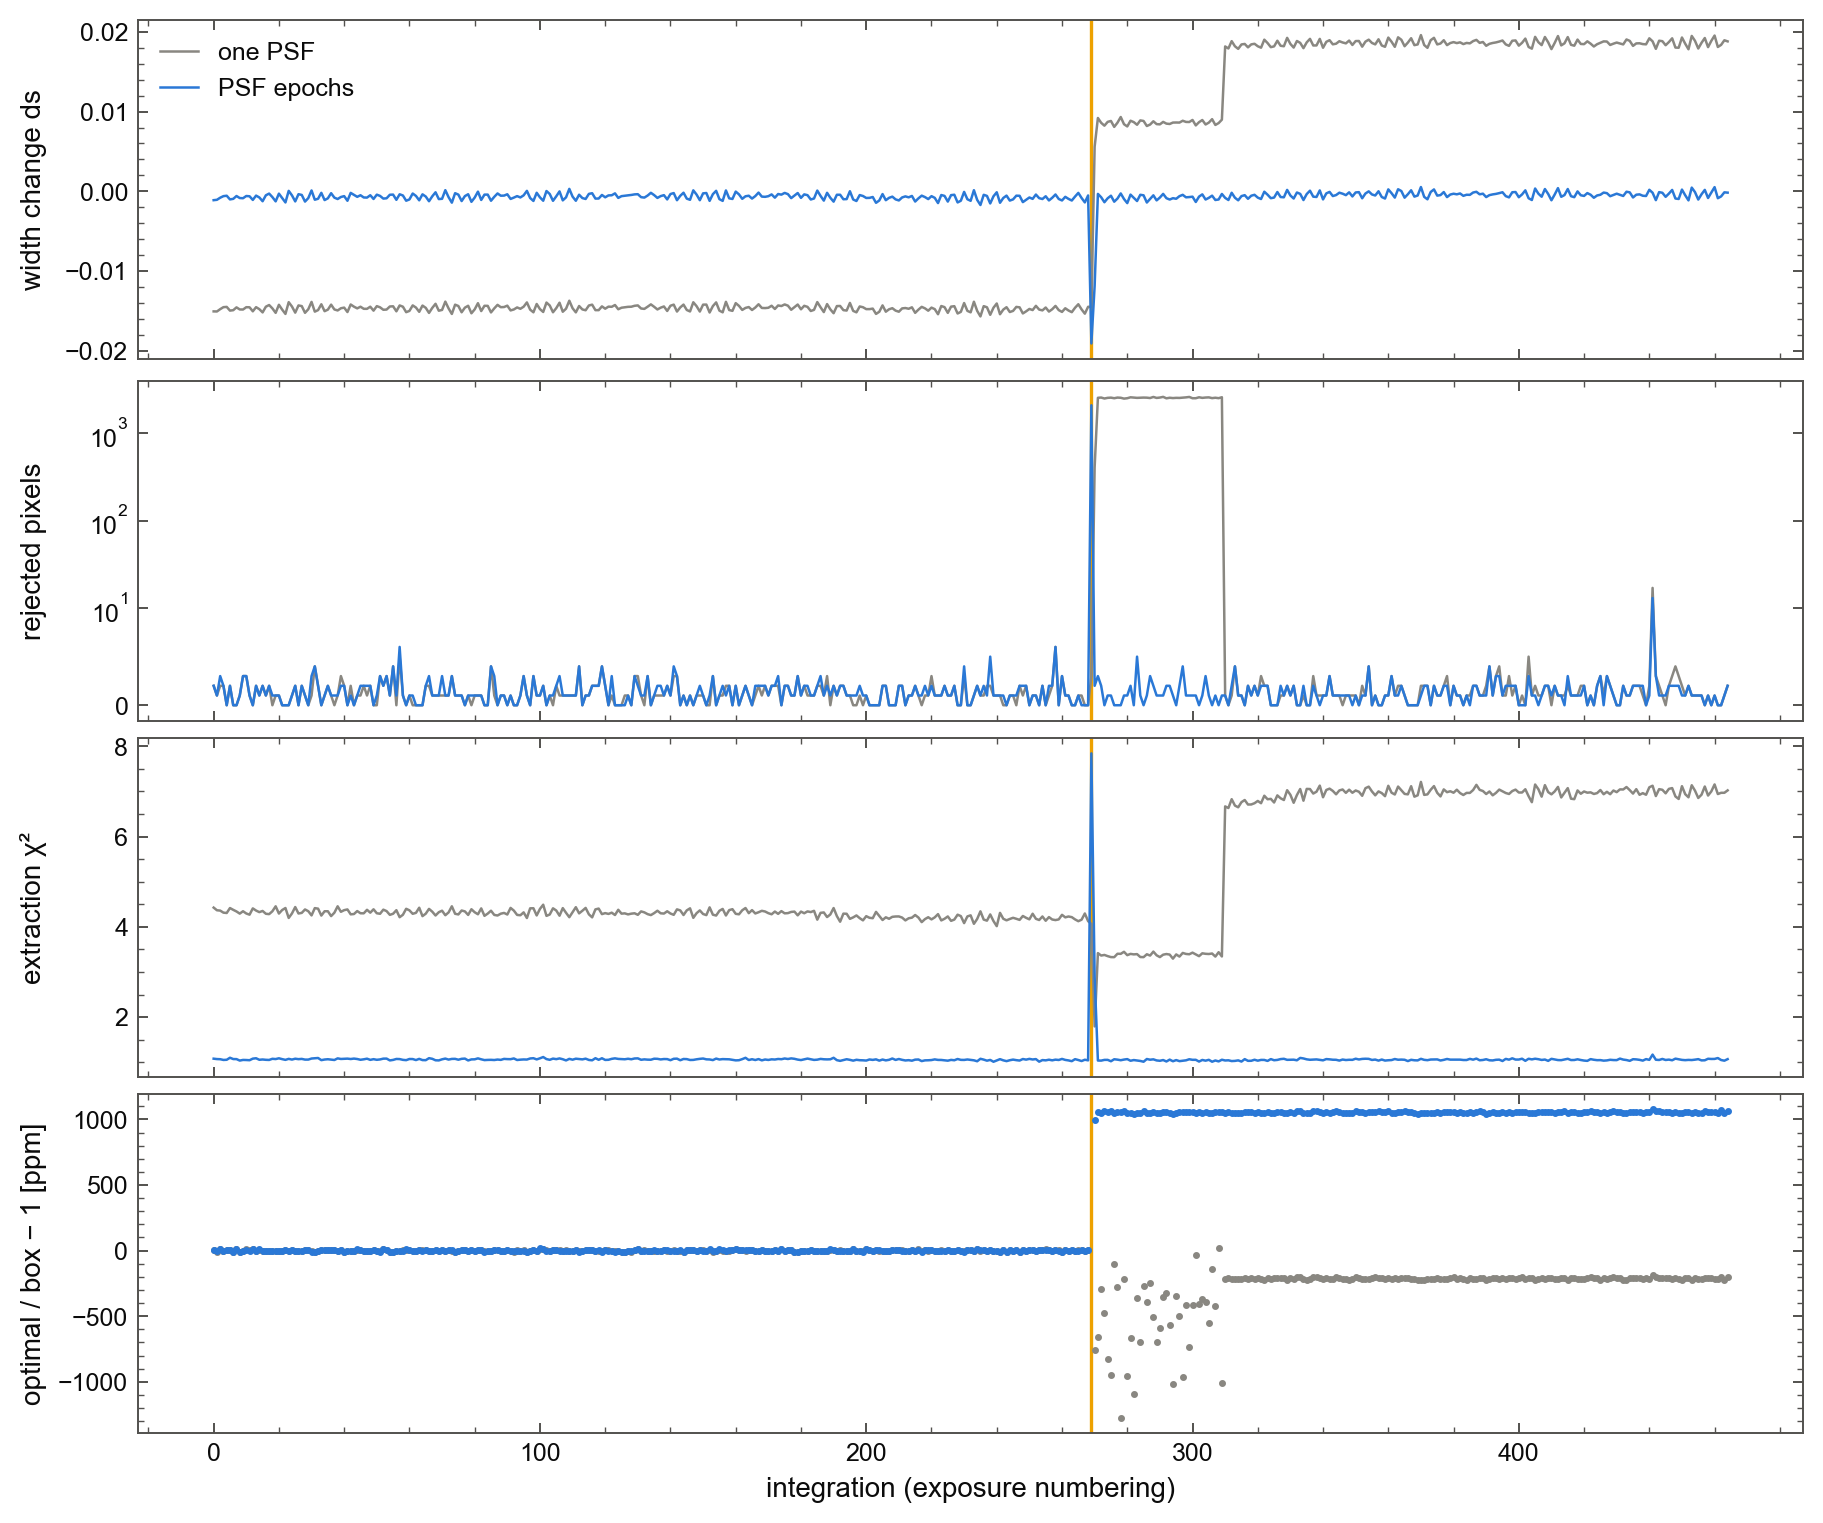

In [16]:
for d in spec_one:
    r = spec_one[d].regressors[1]
    for f in find_psf_breaks({'dy': r['dy'], 'ds': r['ds']}):
        print(f"{d}: step in {f['key']} at integration {f['gidx']}, score {f['score']:.0f}")
tilt_panels([('one PSF', spec_one['NRS1'], 0), ('PSF epochs', spec['NRS1'], 0)]);

Two things to note in the extraction with one PSF:

* The rejections break down only in integrations 270-309, the end of
  segment 2, whose chunk mostly holds pre-tilt integrations. Segment 3
  (all post-tilt) has its own median residuals and looks normal, so a
  plot of segment 3 alone would not reveal the problem.
* The break finder also reports a step at 309, where the rejections stop.
  That is a consequence of the bad extraction, and it disappears with the
  epochs. Check the regressors before adding breaks.

<div class="alert alert-info">

**Comparison with the published light curves**

Our light curves were divided by those of two published reductions of the
same data, in the same wavelength bins, and the ratio fitted with a fixed
transit shape, a linear trend and a step at the tilt (integrations < 15 and
269 left out). The difference of the transit depths, per band (weighted
means over the bins, ppm):

| Detector, band (µm) | jstark − ERS benchmark (Eureka!, native bins) | jstark − ExoTiC-JEDI (10-px bins) |
| --- | --- | --- |
| NRS1 2.70-3.00 | −9.5 ± 5.2 | −17.0 ± 7.2 |
| NRS1 3.00-3.30 | −1.3 ± 3.6 | −6.0 ± 5.2 |
| NRS1 3.30-3.72 | +4.8 ± 3.2 | +4.0 ± 4.4 |
| NRS2 3.82-4.20 | +3.8 ± 4.3 | +3.7 ± 4.9 |
| NRS2 4.20-4.60 | −10.6 ± 6.5 | −17.4 ± 7.6 |
| NRS2 4.60-5.18 | −7.5 ± 8.7 | −1.9 ± 10.0 |

The depths agree within 17 ppm in every band, and the noise per bin is the
same (ratio 1.00-1.01). With one PSF instead of epochs, the optimal depths
were +150 to +340 ppm too deep on NRS1 and +170 ppm at 3.8-4.2 µm on NRS2.
Box and optimal extraction give the same depths and noise here: with 70
groups the light curves are photon-limited, and the optimal weights gain
nothing (white-light scatter 124 ppm box, 128 ppm optimal on NRS1). The
ERS column `x` is our column − 5 (found from the shared noise); for the same
photons the two wavelength solutions agree to better than 0.1 nm.

</div>

## 5. White-light fits with a step

One fit per detector, over the wavelength range of the ERS bins. The
systematics are linear in time and in the trace offset `dy`, plus a
**step at the tilt: the `epoch` regressor** of the extraction (0 before
integration 269, 1 after). The width `ds` and `dx` must not be used as
regressors (they follow the transit through the brighter-fatter effect; see
the PRISM tutorial).

Two sets of integrations are dropped:

* 0-14: the detector settles in the first ~15 minutes (instead of fitting
  a ramp as for PRISM: with 465 integrations a ramp costs more than the 15
  integrations);
* 269: the tilt happened during it.

In [17]:
P, T0 = 4.0552842518, 2459791.6120684328           # ERS benchmark ephemeris
EXCLUDE = [(0, 15), (TILT, TILT + 1)]

def ers_table(det, binning):
    return Table.read(f'{PUB}/ZENODO/4_TRANSMISSION_SPECTRA/Fit_LimbDarkening/'
                      f'NIRSpec_G395H_{det}/{binning}.csv')

white = {}
for det in spec:
    wdir = f'{OUT}/fits/white_{det}'
    if RUN_FULL:
        ers = ers_table(det, 'bins_scale1')
        lc = LightCurves.from_spectra(spec[det].fname, name=det)
        lc = lc.select_channels(wave_range=(ers['wave_low'][0], ers['wave_hig'][-1]))
        lc = lc.exclude(ints=EXCLUDE)
        pri = {'P_p1': ('fixed', P), 't0_p1': ('normal', [T0, 0.002]),
               'p_p1': ('uniform', [0.1, 0.2]), 'b_p1': ('uniform', [0., 1.]),
               'a_p1': ('uniform', [5., 20.]), 'ecc_p1': ('fixed', 0.), 'omega_p1': ('fixed', 90.),
               f'q1_{det}': ('uniform', [0., 1.]), f'q2_{det}': ('uniform', [0., 1.])}
        fit = BroadbandFit({det: lc}, priors=pri, out_folder=wdir,
                           linear=['time', 'dy', 'epoch'])
        fit.fit(sampler='dynamic_dynesty', nthreads=8)      # 40 s
    white[det] = BroadbandFit.load(wdir)

Detected dynamic_dynesty sampler output files --- extracting from /Volumes/Jayshil SSD/JWST/jwst-ers/NRSG395H/Outputs/fits/white_NRS1/_dynesty_DNS_posteriors.pkl
Detected dynamic_dynesty sampler output files --- extracting from /Volumes/Jayshil SSD/JWST/jwst-ers/NRSG395H/Outputs/fits/white_NRS2/_dynesty_DNS_posteriors.pkl


In [18]:
def val(fit, name):
    t = fit.summary(save=False)
    row = t[list(t['name']).index(name)]
    return row['median'], 0.5 * (row['err_plus'] + row['err_minus'])

# the epoch regressor is standardised in the fit: convert its coefficient to a step in flux
lc = LightCurves.from_spectra(spec['NRS1'].fname).exclude(ints=EXCLUDE)
sd = np.std(lc.regressor('epoch')[0])

rows = [('Rp/R*', 'p_p1', 1, '{:.5f} ± {:.5f}'), ('depth [ppm]', 'depth_p1_ppm', 1, '{:.0f} ± {:.0f}'),
        ('b', 'b_p1', 1, '{:.4f} ± {:.4f}'), ('a/R*', 'a_p1', 1, '{:.3f} ± {:.3f}'),
        ('t0 − ERS [s]', 't0_p1', 86400, '{:+.1f} ± {:.1f}'),
        ('step at the tilt [ppm]', 'theta2_{det}', 1e6 / sd, '{:.0f} ± {:.0f}'),
        ('jitter [ppm]', 'sigma_w_{det}', 1, '{:.0f} ± {:.0f}')]
print(f"{'':24s}{'NRS1':>22s}{'NRS2':>22s}")
for lab, name, scale, fmt in rows:
    out = []
    for det in white:
        v, e = val(white[det], name.format(det=det))
        if name == 't0_p1':
            v -= T0
        out.append(fmt.format(v * scale, e * scale))
    print(f'{lab:24s}{out[0]:>22s}{out[1]:>22s}')

                                          NRS1                  NRS2
Rp/R*                        0.14631 ± 0.00016     0.14664 ± 0.00020
depth [ppm]                         21405 ± 47            21503 ± 58
b                              0.4466 ± 0.0048       0.4466 ± 0.0062
a/R*                            11.421 ± 0.024        11.393 ± 0.032
t0 − ERS [s]                        -3.4 ± 1.4            +5.0 ± 1.9


step at the tilt [ppm]              -975 ± 122            -864 ± 153
jitter [ppm]                            74 ± 7               104 ± 9


| | NRS1 | NRS2 | ERS benchmark |
| --- | --- | --- | --- |
| $R_p/R_*$ | 0.14631 ± 0.00016 | 0.14664 ± 0.00020 | 0.14613 / 0.14678 |
| $b$ | 0.4466 ± 0.0049 | 0.4466 ± 0.0062 | 0.4498 |
| $a/R_*$ | 11.421 ± 0.024 | 11.393 ± 0.032 | 11.390 |

$R_p/R_*$ agrees with the benchmark within about 1σ on each detector, and
so does the geometry (the benchmark orbit is a joint fit of all JWST, TESS
and ground-based data). The fitted step agrees with the jump of the optimal
white light seen in Section 4. Mid-transit is measured to 1-2 s on each
detector; the two detectors differ by 8.5 ± 2.4 s, although they record the
same photons at the same times (not understood).

NRS1: residual rms 122 ppm; integration 270: +721 ppm


NRS2: residual rms 165 ppm; integration 270: +730 ppm


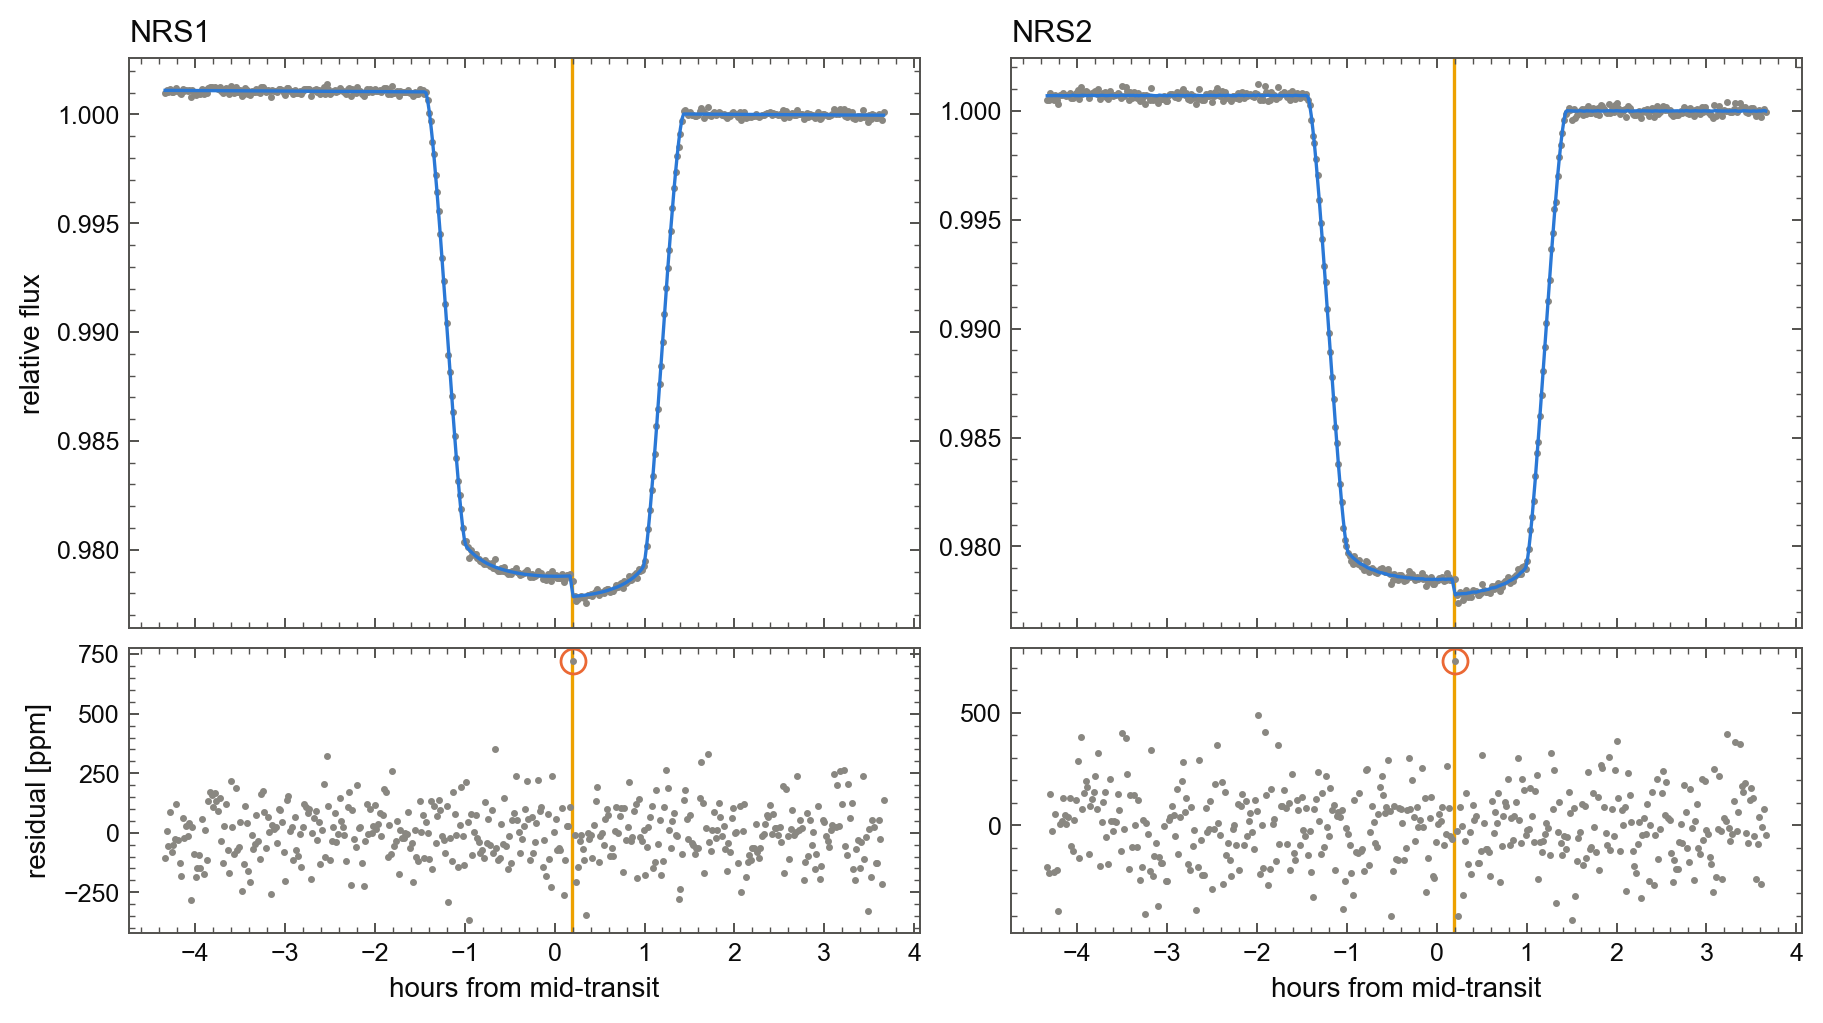

In [19]:
fig, axs = plt.subplots(2, 2, figsize=(9, 5), sharex=True, layout='constrained',
                        gridspec_kw=dict(height_ratios=[2, 1]))
for k, det in enumerate(white):
    res = white[det].residuals(det)
    th = (res['t'] - T0) * 24
    t270 = (spec[det].bjd[TILT + 1] - T0) * 24
    axs[0, k].plot(th, res['y'], '.', ms=3, color='#898781')
    axs[0, k].plot(th, res['model'], '-', color='C0', lw=1.2)
    axs[1, k].plot(th, 1e6 * res['resid'], '.', ms=3, color='#898781')
    i = np.argmin(np.abs(th - t270))
    axs[1, k].plot(th[i], 1e6 * res['resid'][i], 'o', mfc='none', mec='C1', ms=9)
    for a in axs[:, k]:
        a.axvline((spec[det].bjd[TILT] - T0) * 24, color='#eda100', lw=1.2, zorder=0)
    axs[0, k].set_title(det)
    axs[1, k].set_xlabel('hours from mid-transit')
    print(f'{det}: residual rms {1e6 * np.std(res["resid"]):.0f} ppm; '
          f'integration 270: {1e6 * res["resid"][i]:+.0f} ppm')
axs[0, 0].set_ylabel('relative flux'); axs[1, 0].set_ylabel('residual [ppm]');

<div class="alert alert-info">

**Integration 270, and which integrations to drop at a tilt**

The first integration after the tilt (270, circled) is a 5-7σ outlier on
both detectors, +720 ppm: the mirror had not fully settled. The ExoTiC-JEDI
reduction of Alderson et al. (2023) drops 269-271. Refitting without
269-271 changes the depths by +21 and +16 ppm (0.4σ), the geometry not at
all, and lowers the jitter (74 → 65 and 104 → 98 ppm). The effect is small
here, but for a tilt in your data drop the tilt integration **and the next
one or two**: `exclude(ints=[(0, 15), (269, 272)])`.

The white light scatters 15-25% above its propagated errors (the native
spectral bins only 4-6%): a small noise common to all columns, which the
jitter term absorbs.

</div>

## 6. Transmission spectrum

`SpectroscopicFit` fits each bin with the orbit fixed to the white-light
medians of its detector, and its own $R_p/R_*$, limb darkening (q1, q2
free), linear trend, `dy`, step and jitter. Two binnings of the ERS
benchmark: R ≈ 100 (30 + 29 bins, 260 s per detector with 8 processes)
and the native bins of ~3 columns (488 + 675 bins, 2.1 h for both).

In [20]:
def spectroscopic(det, binning):
    sdir = f'{OUT}/fits/spec_{det}_{binning}'
    if RUN_FULL:
        ers = ers_table(det, binning)
        lc = LightCurves.from_spectra(spec[det].fname, name=det).exclude(ints=EXCLUDE)
        pri = white[det].channel_priors(fix=('P', 't0', 'a', 'b', 'ecc', 'omega'))
        pri.update({'p_p1': ('uniform', [0.05, 0.25]),
                    f'q1_{det}': ('uniform', [0., 1.]), f'q2_{det}': ('uniform', [0., 1.])})
        sf = SpectroscopicFit({det: lc}, priors=pri, out_folder=sdir,
                              edges=np.stack([ers['wave_low'], ers['wave_hig']], axis=1),
                              linear=['time', 'dy', 'epoch'])
        sf.run(nproc=8)
    t = Spectrum.read(f'{sdir}/spectrum.ecsv')
    return dict(bin=np.asarray(t['bin']), wave=np.asarray(t['wave']),
                lo=np.asarray(t['wave_lo']), hi=np.asarray(t['wave_hi']),
                d=np.asarray(t['depth_p1_ppm']),
                e=0.5 * np.asarray(t['depth_p1_ppm_errp'] + t['depth_p1_ppm_errm']))

def ers_depth(det, binning, bins):
    t = ers_table(det, binning)
    rp = np.asarray(t['rp/rs'])[bins]
    return rp ** 2 * 1e6, rp * np.asarray(t['rp/rs_err_low'] + t['rp/rs_err_hih'])[bins] * 1e6

def alderson_on(lo, hi):
    '''Alderson et al. (2023) weighted-average spectrum (10-pixel bins), inverse-variance
    averaged onto our bins (bins holding at least two of theirs).'''
    a = xr.open_dataset(f'{PUB}/alderson2023/G395H_paper_data/3_TRANSMISSION_SPECTRA/'
                        'transit-spectrum-W39b-G395H-10pix_weighted-average.nc')
    w, d = a.central_wavelength.values, a.transit_depth.values * 1e6
    e = np.mean([a[k].values for k in a.data_vars if 'err' in k], axis=0) * 1e6
    out, err = np.full(lo.size, np.nan), np.full(lo.size, np.nan)
    for k, (x0, x1) in enumerate(zip(lo, hi)):
        s = (w >= x0) & (w < x1) & np.isfinite(d)
        if s.sum() >= 2:
            iv = 1 / e[s] ** 2
            out[k], err[k] = np.sum(iv * d[s]) / iv.sum(), iv.sum() ** -0.5
    return out, err

def compare(diff, e1, e2):
    ok = np.isfinite(diff) & np.isfinite(e2)            # bins covered by both spectra
    diff, e1, e2 = diff[ok], e1[ok], e2[ok]
    off = np.median(diff)
    z = (diff - off) / np.hypot(e1, e2)
    return (f'offset {off:+4.0f} ppm, rms after it {np.std(diff - off):3.0f} ppm, '
            f'error ratio {np.median(e1 / e2):.2f}, bins beyond 3σ: {np.sum(np.abs(z) > 3)}')

NRS1 vs ERS:             offset  +20 ppm, rms after it  50 ppm, error ratio 0.98, bins beyond 3σ: 0
NRS1 vs Alderson average: offset -142 ppm, rms after it  56 ppm, error ratio 1.09, bins beyond 3σ: 0
NRS2 vs ERS:             offset  -40 ppm, rms after it  40 ppm, error ratio 1.00, bins beyond 3σ: 0
NRS2 vs Alderson average: offset  -50 ppm, rms after it  47 ppm, error ratio 1.11, bins beyond 3σ: 0


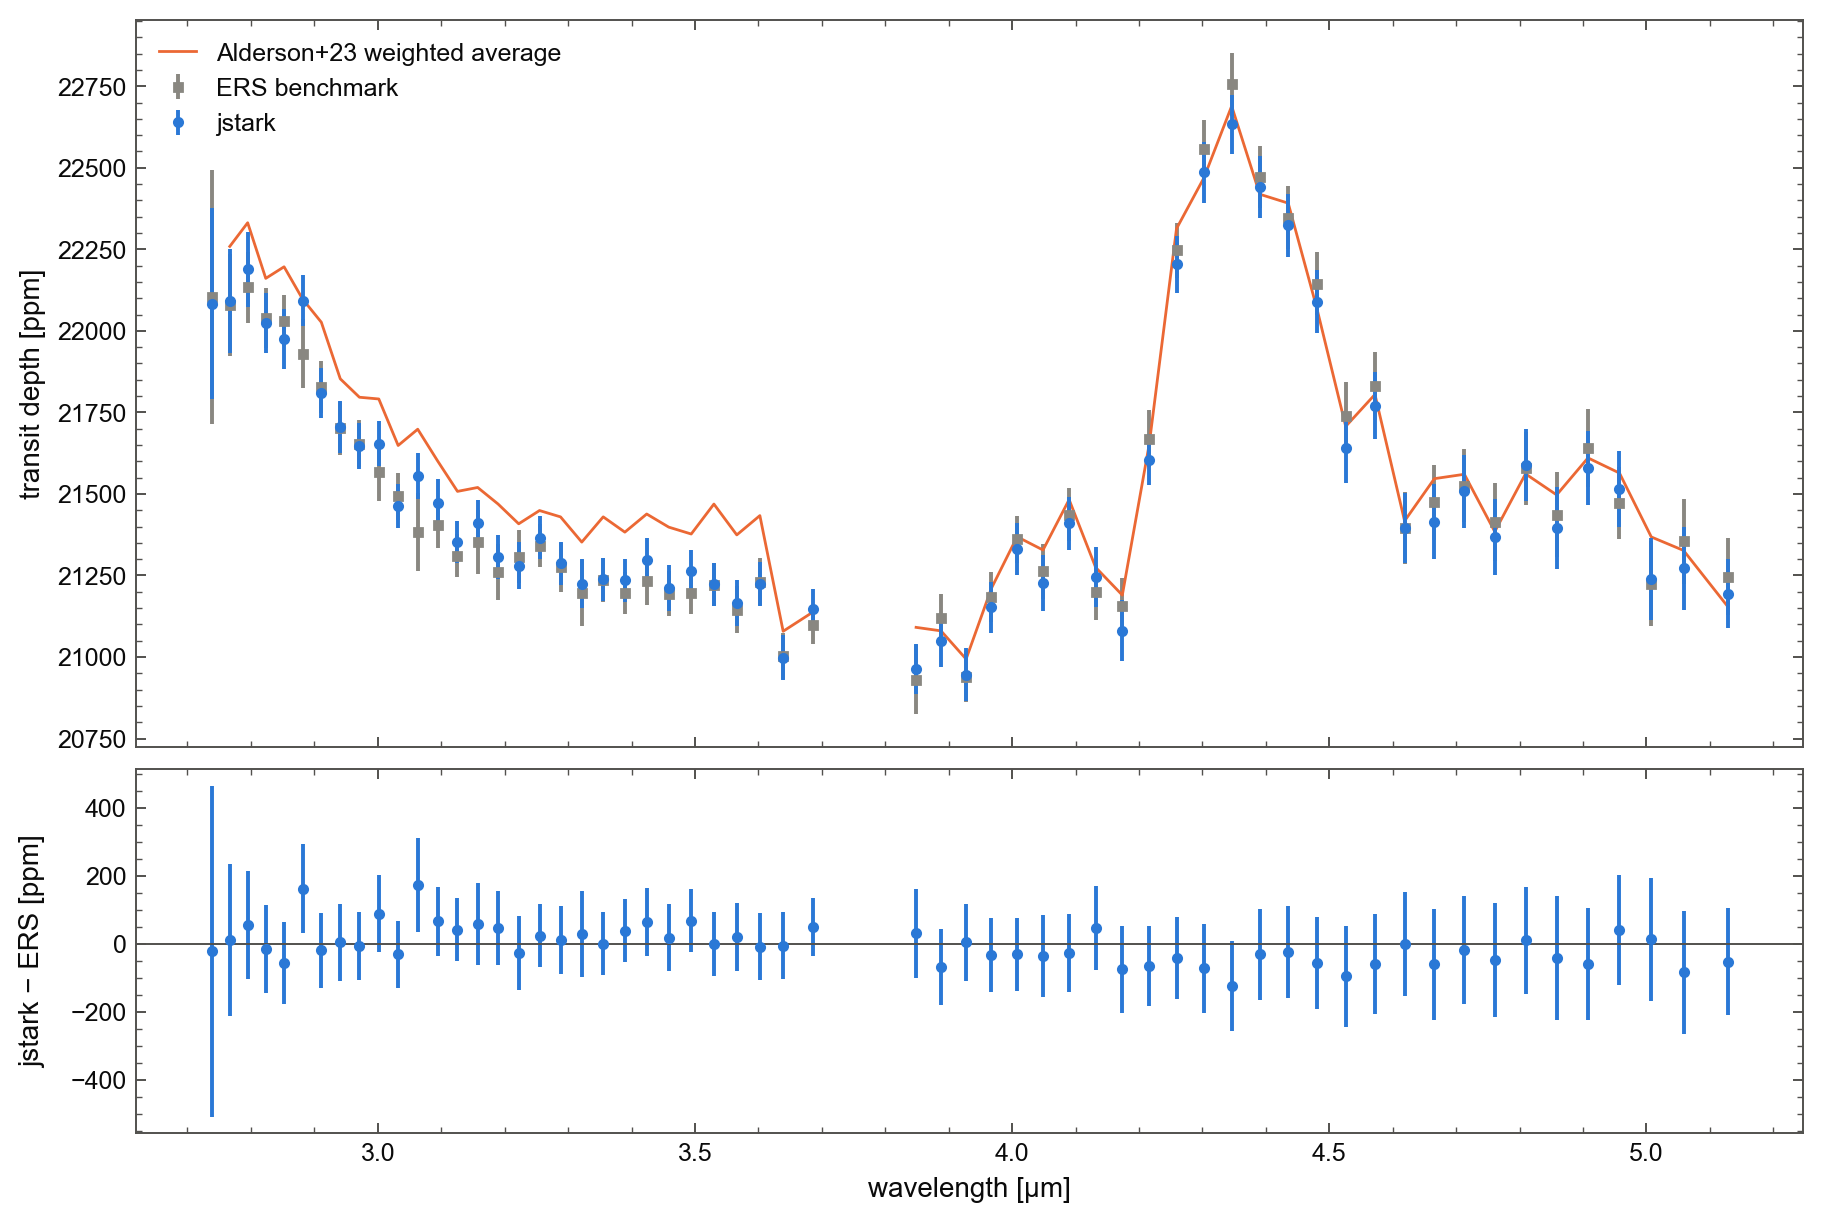

In [21]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True, layout='constrained',
                             gridspec_kw=dict(height_ratios=[2, 1]))
for det in ('NRS1', 'NRS2'):
    o = spectroscopic(det, 'R100')
    pd, pe = ers_depth(det, 'R100', o['bin'])
    ad, ae = alderson_on(o['lo'], o['hi'])
    first = det == 'NRS1'
    a1.errorbar(o['wave'], pd, pe, fmt='s', ms=3, color='#898781', label='ERS benchmark' if first else None)
    a1.plot(o['wave'], ad, '-', color='C1', lw=1, label='Alderson+23 weighted average' if first else None)
    a1.errorbar(o['wave'], o['d'], o['e'], fmt='o', ms=3, color='C0', label='jstark' if first else None)
    a2.errorbar(o['wave'], o['d'] - pd, np.hypot(o['e'], pe), fmt='o', ms=3, color='C0')
    print(f'{det} vs ERS:            ', compare(o['d'] - pd, o['e'], pe))
    print(f'{det} vs Alderson average:', compare(o['d'] - ad, o['e'], ae))
a2.axhline(0, color='#52514e', lw=0.7)
a1.set_ylabel('transit depth [ppm]'); a1.legend(loc='upper left')
a2.set_ylabel('jstark − ERS [ppm]'); a2.set_xlabel('wavelength [µm]')
fig.align_ylabels((a1, a2));

The spectrum reproduces the benchmark bin by bin, with the same error bars:
the H$_2$O slope on NRS1, SO$_2$ at 4.05 µm and CO$_2$ at 4.3 µm. The
offsets (+20 and −40 ppm against the benchmark, −142 and −50 ppm against
the weighted average of Alderson et al.) are typical of independent
reductions of the same data: the 11
reductions of Alderson et al. (2023) differ from ours by −357 to +77 ppm
(NRS1) and −211 to +151 ppm (NRS2), and our spectrum lies within their
spread.

In [22]:
for det in ('NRS1', 'NRS2'):
    o = spectroscopic(det, 'bins_scale1')
    pd, pe = ers_depth(det, 'bins_scale1', o['bin'])
    print(f'{det}, {len(o["bin"])} native bins vs ERS:', compare(o['d'] - pd, o['e'], pe))
    q = np.array_split(np.arange(len(o['bin'])), 5)
    print('    error ratio jstark / ERS from blue to red:',
          ', '.join(f"{o['wave'][i].mean():.2f} µm {np.median(o['e'][i] / pe[i]):.2f}" for i in q))

NRS1, 488 native bins vs ERS: offset  +40 ppm, rms after it 235 ppm, error ratio 0.96, bins beyond 3σ: 0
    error ratio jstark / ERS from blue to red: 2.82 µm 0.87, 3.02 µm 0.97, 3.22 µm 0.98, 3.42 µm 0.97, 3.62 µm 0.96
NRS2, 675 native bins vs ERS: offset   +3 ppm, rms after it 287 ppm, error ratio 0.80, bins beyond 3σ: 0
    error ratio jstark / ERS from blue to red: 3.96 µm 0.91, 4.24 µm 0.83, 4.51 µm 0.80, 4.77 µm 0.73, 5.04 µm 0.72


<div class="alert alert-info">

**The error bars at native resolution**

In the native bins, the depths agree with the benchmark as well (no bin
beyond 3σ), but our error bars on NRS2 are smaller than the benchmark's,
from 9% at 3.96 µm to 28% at 5.04 µm. The light curves are not the reason:
the scatter of our native-bin light curves matches that of the ERS light
curves to 1% at every wavelength. Limb darkening is not the reason either:
the benchmark's errors with *fixed* limb darkening are nearly as large.

Our errors are 1.05-1.10 times what a least-squares fit with fixed limb
darkening gives for the measured residual scatter (the cost of the free
limb darkening and the systematics), and the residuals show no red noise.
The benchmark's errors grow to 1.47 times that level at 5 µm. This points to
an inflation of the errors on their side that the released tables do not
document, not to underestimated errors here. At R ≈ 100 the two agree.

</div>

## 7. Summary: how to handle a jump

| Step | What to do | Why (these data) |
| --- | --- | --- |
| Look | `xdiag.plot_regressors(spec)`; the warning from `run()` | the tilt scores 63-91 in `ds`; normal visits < 10 |
| Extract | `ex.set('psf', breaks=[269])` (break = first integration of the new epoch) | one PSF: χ² 4-7, 2,500 pixels rejected per integration, depths +150 to +340 ppm |
| Fit | `linear=[..., 'epoch']`, the step the extraction saves | box −1900 ppm, optimal −900 ppm at the tilt, in the transit |
| Drop | the tilt integration and the next one or two | 269 is a mix of both PSFs; 270 is +720 ppm off |
| Never | `ds` or `dx` as regressors in transit fits | they follow the transit (brighter-fatter) |

And two defaults that these data changed for every NIRSpec reduction:

| Stage | Change | Evidence |
| --- | --- | --- |
| Stage 1 | static bad pixels (and their grown neighbours) left out of the saturation map | 13 NRS2 columns were lost |
| Extraction | PSF epochs (`psf breaks`) and the break warning | depths within 17 ppm of two published reductions |

The result: on both detectors, light curves with the noise of the published
reductions, and a spectrum that matches the ERS benchmark within its
errors at R ≈ 100 and at native resolution.